In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Due to a Jupyter bug, the %matplotlib inline "magic" command needs to be in 
# its own cell. See:
# https://github.com/jupyter/notebook/issues/3385

%matplotlib inline

In [3]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

# Adjust default font size so that labels are readable in plots
font = {'size': 18}
matplotlib.rc('font', **font)

# Bootstrap and Jackknife

## Bootstrap and Jackknife versus Monte Carlo

Approaches we have seen so far generally assume that one has well-defined model for the parent population distribution (even if it has some unknown parameters). 

In these cases, one can usually calculate the confidence limits analytically, or if this is not possible, at least simulate them via Monte Carlo.

It is sometimes the case that one does not have a _good model_ for the _parent_ population distribution.

But you still want to be able to estimate uncertainties for the statistics that you calculate.

The key idea is to use the data themselves in place of the (unknown) parent distribution.

## Bootstrap method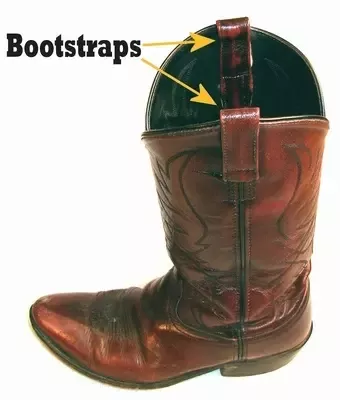

Suppose you have a sample of $N$ data, ${x_i}$ and you calculate some statistic $S(\bf{x})$

The algorithm is:

First, draw a bootstrap resample of size $N$ from your original sample, with _replacement_. By this we mean that a data point is allowed to be repeated. At the end of this process, some of the original data will not appear at all, some will appear once, some twice etc.

Second, measure your statistic $S$ on the bootstrap resample. Save the result.

Repeat the bootstrap resampling $M$ times, where $M$ is a large number e.g. 1000. 

Plot a histogram of the $M$ versions of the statistic, calculate its standard deviation, etc.

In [4]:
from astropy.stats import bootstrap
data = np.arange(10)
print(data)

[0 1 2 3 4 5 6 7 8 9]


In [5]:
bootresult = bootstrap(data, 5)
print(bootresult)

[[7. 8. 2. 2. 2. 6. 6. 2. 9. 2.]
 [4. 5. 1. 6. 7. 4. 9. 9. 2. 5.]
 [9. 3. 9. 2. 0. 1. 7. 7. 3. 2.]
 [5. 4. 2. 9. 1. 1. 2. 2. 2. 8.]
 [7. 4. 0. 2. 5. 3. 3. 7. 3. 1.]]


In [6]:
bootresult = bootstrap(data, 5, bootfunc=np.median) # execute bootfunc along rows
print(bootresult)

[6. 6. 6. 5. 2.]


Data mean: -0.3250086528647944
Formal uncertainty on mean: 0.3333333333333333
Bootstrap mean of means -0.3268355217549347
Bootstrap std of means: 0.31351810566881305


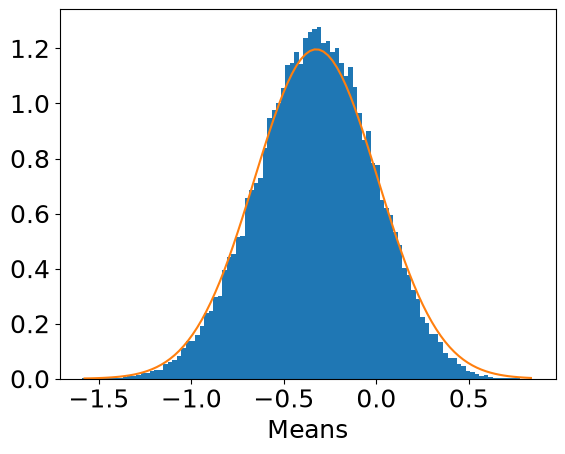

In [7]:
from astropy.stats import bootstrap
from scipy.stats import norm

N = 9
data = np.random.normal(size=N)
data_mean = np.mean(data)
data_stemean = 1./np.sqrt(N)
print("Data mean:", data_mean)
print("Formal uncertainty on mean:", data_stemean)

bootmeans = bootstrap(data, 100_000, bootfunc=np.mean)
print("Bootstrap mean of means", np.mean(bootmeans))
print("Bootstrap std of means:", np.std(bootmeans, ddof=1))
h, edges, patch = plt.hist(bootmeans, bins=100, density=True)
centres = (edges[1:]+edges[:-1])/2.
plt.plot(centres, norm(loc=data_mean, scale=data_stemean).pdf(centres))
plt.xlabel("Means");

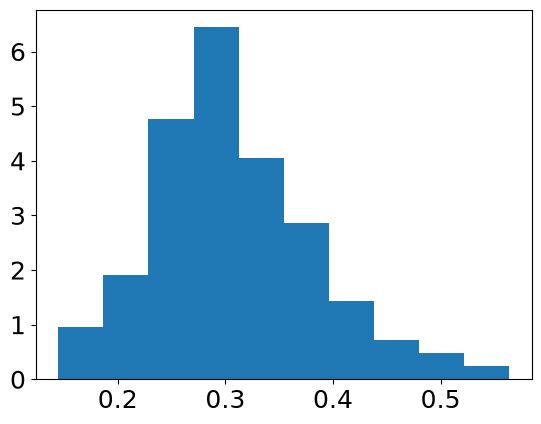

In [8]:
hist = []
for i in range(100):
    data = np.random.normal(size=N)
    bootmeans = bootstrap(data, 1_000, bootfunc=np.mean)
    hist.append(np.std(bootmeans, ddof=1))
h, edges, patch = plt.hist(hist, bins=10, density=True)

Where the bootstrap comes in handy is where, either 

1. you know nothing about the parent distribution 
2. you are calculating a complicated statistic for which you have no insight into the analytic expression

or both

Data mean after dropping hi/lo: -0.060777662139072874
Bootstrap mean of means -0.07341286416423957
Bootstrap std of means: 0.3841699506647679


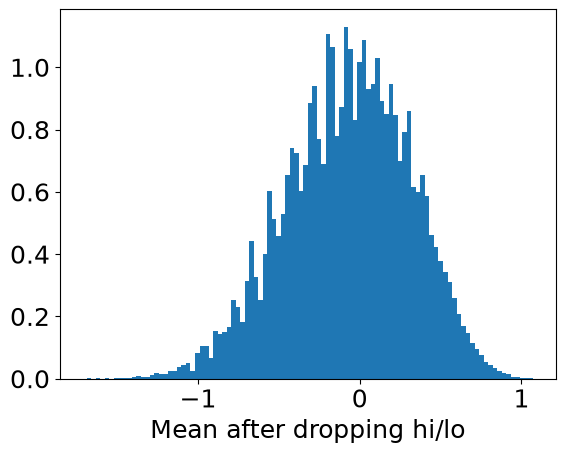

In [9]:
from astropy.stats import bootstrap
from scipy.stats import norm

def clipped_mean(data):
    return np.mean(np.sort(data)[1:-1])

N = 9
data = np.random.normal(size=N)
data_mean = clipped_mean(data)
print("Data mean after dropping hi/lo:", data_mean)

bootmeans = bootstrap(data, 100_000, bootfunc=clipped_mean)
print("Bootstrap mean of means", np.mean(bootmeans))
print("Bootstrap std of means:", np.std(bootmeans, ddof=1))
h, edges, patch = plt.hist(bootmeans, bins=100, density=True)
centres = (edges[1:]+edges[:-1])/2.
plt.xlabel("Mean after dropping hi/lo");

In practice, bootstrap is very easy to implement operationally, even with long and complex data files.

Suppose you have a data file and some analysis code that reads the data and produces some output.

All you need to is separately prepare some bootstrap input data files, and then write a script to loop over all of these calling the original code (saving the results of course) with a bootstrap file as input. 

The nice thing is that no modification to the analysis code is necessary, since the bootstrapped data has the same structure and length as the original data file.

For example if your data is a simple ascii table, with $M$ columns of data, you would resample from the $N$ rows of data, producing a new file ``boot1.dat`` with $N$ rows.

``python mycode.py boot1.dat``

``python mycode.py boot2.dat``

...

``python mycode.py boot1000.dat``

## Jackknife

Introduction

In this method, one makes a jackknife sample by dropping one data point from the sample, and recalculating the statistic. Then one loops over each data entry in turn.

In some cases, the jackknife  can be biased, but it is usually possible to make a bias correction, and to estimate the standard deviation of the population from the jacknife samples.

See SDMMLA, Section 4.5

Suppose $\theta$ is the target parameter of interest, which is assumed to be some functiom of the distribution of $x$. Based on a finite set of observations $x_1, ..., x_n$, 

$$\hat{\theta} =f_n(x_1,\ldots,x_n).$$

The value of $\hat{\theta}$ is sample-dependent, so this value will change from one random sample to another. 

We construct the jackknife replicates:

$\hat{\theta}_{(1)} =f_{n-1}(x_{2},x_{3}\ldots,x_{n})$

$\hat{\theta}_{(2)} =f_{n-1}(x_{1},x_{3},\ldots,x_{n})$

$\vdots$

$\hat{\theta}_{(n)} =f_{n-1}(x_1,x_{2},\ldots,x_{n-1})$

where each replicate is a "leave-one-out" estimate based on the jackknife subsample consisting of all but one of the data points

Then we define their average:

$$
\hat{\theta}_\mathrm{jack}=\frac{1}{n} \sum_{i=1}^n \hat{\theta}_{(i)}
$$

By definition, the bias of $\hat{\theta}$ is

$\text{bias}(\hat{\theta}) = E[\hat{\theta}] - \theta.$


The jackknife estimate of the bias of $\hat{\theta}$ is given by:

$$\widehat{\text{bias}}(\hat{\theta})_\mathrm{jack} =(n-1)(\hat{\theta}_\mathrm{jack} - \hat{\theta})
$$

The jacknife estimate of the variance is 

\begin{align*}
\widehat{\operatorname{Var}}(\theta)_{\mathrm{jack}}
& =\frac{n-1}{n} \sum_{i=1}^n\left(\widehat{\theta}_{(i)}-\widehat{\theta}_{\textrm{jack}}\right)^2
\\
& =\frac{(n-1)^2}{n} \times\left(s^2 \text { for the } \widehat{\theta}_{(i)} \text { values }\right)
\end{align*}

For example, if the parameter to be estimated is the population mean of random variable $x$, then for a given set of i.i.d. observations $x_1, ..., x_n$ the natural estimator is the sample mean:

$$
\bar{x} =\frac{1}{n} \sum_{i=1}^{n} x_i =\frac{1}{n} \sum_{i \in [n]} x_i
$$

where the last sum used another way to indicate that the index $i$ runs over the set $[n] = \{ 1,\ldots,n\}$.

Then we proceed as follows: for each $i \in [n]$ we compute the mean $\bar{x}_{(i)}$ of the jackknife subsample consisting of all but the $i$-th data point, and this is called the $i$-th jackknife replicate:

$$\bar{x}_{(i)} =\frac{1}{n-1} \sum_{j \in [n], j\ne i} x_j, \quad \quad i=1, \dots ,n.$$

A jackknife estimate of the variance of $\bar{x}$ can be calculated from the variance of the jackknife replicates $\bar{x}_{(i)}$ and the mean of the replicates $\bar{x}_{\mathrm{jack}}$:

$$
\widehat{\operatorname{Var}}(\bar{x})_{\mathrm{jack}}
=\frac{n-1}{n} \sum_{i=1}^n (\bar{x}_{(i)} - \bar{x}_{\mathrm{jack}})^2.
$$

In [10]:
import numpy as np
from astropy.stats import jackknife_resampling
from astropy.stats import jackknife_stats
data = np.random.randn(5)
print(data)
resamples = jackknife_resampling(data)
print(resamples)

[ 0.13871572 -0.37511641  0.10564943  0.41195229  0.36452475]
[[-0.37511641  0.10564943  0.41195229  0.36452475]
 [ 0.13871572  0.10564943  0.41195229  0.36452475]
 [ 0.13871572 -0.37511641  0.41195229  0.36452475]
 [ 0.13871572 -0.37511641  0.10564943  0.36452475]
 [ 0.13871572 -0.37511641  0.10564943  0.41195229]]


Let's try estimating the mean with a larger sample

In [15]:
N = 100
data = np.random.randn(N)

test_statistic = np.mean
estimate, bias, stderr, conf_interval = jackknife_stats(data, test_statistic, 0.68)
print("Estimate, confidence interval:", estimate, conf_interval)
print("Bias, Std err                :", bias, stderr)

Estimate, confidence interval: -0.0036964012387138536 [-0.10227357  0.09488077]
Bias, Std err                : 8.586881206085195e-17 0.09912653708660023


Now let's try the jackknife with another statistic, the variance

In [27]:
data = np.random.randn(N)
test_statistic = np.var
estimate, bias, stderr, conf_interval = jackknife_stats(data, test_statistic, 0.68)
print("Estimate, confidence interval:", estimate, conf_interval)
print("Bias, Std err                :", bias, stderr)

Estimate, confidence interval: 0.7861957354559472 [0.67353271 0.89885876]
Bias, Std err                : -0.00786195735458195 0.11329089226863308


We need the Bessel correction! In ``numpy`` this is implemented by passing ``ddof =1`` 

In [28]:
data = np.random.randn(N)
test_statistic = lambda x: np.var(x, ddof=1)
estimate, bias, stderr, conf_interval = jackknife_stats(data, test_statistic, 0.68)
print("Estimate, confidence interval:", estimate, conf_interval)
print("Bias, Std err                :", bias, stderr)

Estimate, confidence interval: 0.8816362451656765 [0.74063197 1.02264052]
Bias, Std err                : 1.099120794378905e-14 0.14179008943576688


Finally for the standard deviation

In [ ]:
data = np.random.randn(N)
test_statistic = lambda x: np.std(x, ddof=1)
estimate, bias, stderr, conf_interval = jackknife_stats(data, test_statistic, 0.68)
print("Estimate, confidence interval:", estimate, conf_interval)
print("Bias, Std err                :", bias, stderr)

In Cosmology, for example in calculation of correlation functions, its common to jacknife **not** over individual data points (e.g. galaxies) but over **patches of the sky**.